# Assignment 3 — Sports Analytics

## Task 1: YOLOv11 Object Detection

**Deliverables:**
- Run YOLOv11 on soccer video detecting 'person' and 'sports ball'
- Show representative frame with detections
- Explain single-shot detection pipeline
- Explain and demonstrate NMS
- (Optional) Visualize feature maps

## Task 2: Deep-SORT Tracking

**Deliverables:**
- Architecture diagram
- Explain Kalman filter equations
- Explain Hungarian algorithm
- Implement Deep-SORT tracking
- Track players and ball
- Export annotated video

## Video Setup

## Task 1: YOLOv11 Detection

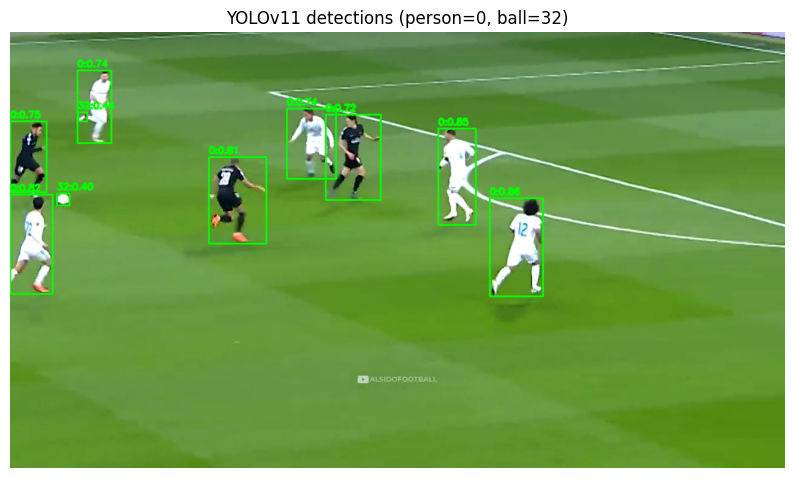

In [3]:

from ultralytics import YOLO
import cv2, numpy as np
import matplotlib.pyplot as plt

MODEL_WEIGHTS = "yolo11n.pt"
model = YOLO(MODEL_WEIGHTS)

VIDEO_PATH = "../assignment-3/data/Football match - LearnOpenCV (720p, h264).mp4"

TARGET_CLASSES = [0, 32] ## person class and sports ball class

## Make sure video exists
cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise RuntimeError(f"Could not open video at {VIDEO_PATH}")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) or 300
mid_idx = total_frames // 2
cap.set(cv2.CAP_PROP_POS_FRAMES, mid_idx)
ok, frame = cap.read()
cap.release()

if not ok:
    raise RuntimeError("Failed to read a representative frame. Check VIDEO_PATH.")

results = model.predict(source=frame, classes=TARGET_CLASSES, verbose=False)

## Draw the boxes with their confidences and classes
def draw_detections(img_bgr, res, conf_thresh=0.25):
    img = img_bgr.copy()
    if not res or not len(res):
        return img
    r = res[0]
    if r.boxes is None:
        return img
    boxes = r.boxes.xyxy.cpu().numpy() if hasattr(r.boxes.xyxy, "cpu") else r.boxes.xyxy
    confs = r.boxes.conf.cpu().numpy() if hasattr(r.boxes.conf, "cpu") else r.boxes.conf
    clss  = r.boxes.cls.cpu().numpy() if hasattr(r.boxes.cls, "cpu") else r.boxes.cls
    for (x1,y1,x2,y2), c, cl in zip(boxes, confs, clss):
        if c < conf_thresh:
            continue
        cv2.rectangle(img, (int(x1),int(y1)), (int(x2),int(y2)), (0,255,0), 2)
        label = f"{int(cl)}:{c:.2f}"
        cv2.putText(img, label, (int(x1), int(y1)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 2, cv2.LINE_AA)
    return img

vis = draw_detections(frame, results, conf_thresh=0.25)

plt.figure(figsize=(10,6))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("YOLOv11 detections (person=0, ball=32)")
plt.show()


### Single-Shot Detection Pipeline Explanation

A single-shot detection pipeline starts with a CNN that extracts all multi-scale feature maps from the input image. Then, large-objects and small-objects are combined so the detector can localize different sized objects. Next, at different spacial locations, bounding boxes offsets, confidence scores, and class probabilities are created. Finally, the relative offsets are converted into absolute box coordinates for the objects.

### Non-Maximum Suppression (NMS) Explanation

A non-maximum suppression takes all of the predicted boxes for a specific class and sorts them by confidence. Then, the box with the highest confidence is used as a keeper for the other boxes nearby. Next, the Intersection over Union (IoU) between the keeper and the remaining boxes is computed and if the IoU exceeds a certain threshold, the box with the lower confidence is removed because it believes they may be the same object.

## Task 2: Deep-SORT Tracking

### Architecture Diagram

<img src="Tracking Diagram.svg" width=400>

### Kalman Filter

The Kalman filter maintains track state using a linear, Gaussian model:

**State vector:** \(x = [u, v, s, r, dotu, dotv, dots]^T) — center coordinates (u, v), scale (s), aspect ratio (r), and velocities.

Tracks everything that we know about the object during a specific point in time.

**Predict step:** F = state transition matrix, P = uncertainty covariance, Q = process noise
- (x_k|k-1 = F * x_k-1|k-1)
- (P_k|k-1 = F P_k-1|k-1 * F^T + Q)

The filter tries to predict where the object should be in the future based on the information from the previous frame.

**Update step:** H = observation model (measurement matrix), R = measurement noise 
- (y_k = z_k - H * x_k|k-1)
- (S_k = H * P_k|k-1 H^T + R)
- (K_k = P_k|k-1 * H^T * S_k^-1)
- (x_k|k = x_k|k-1 + K_k * y_k)
- (P_k|k = (I - K_k * H) * P_k|k-1)

We then get the information that is detected and compare it to the prediction to correct the estimate that was made.

### Hungarian Algorithm

The Hungarian algorithm solves the assignment problem by finding minimum-cost one-to-one matching between predicted tracks and new detections. In Deep-SORT, the cost matrix combines motion distance (Mahalanobis) and appearance similarity (cosine distance on ReID embeddings).

### Implementation

In [ ]:

import numpy as np, cv2, os
from dataclasses import dataclass
from typing import Optional, List
from filterpy.kalman import KalmanFilter
from scipy.optimize import linear_sum_assignment

## Convert XY values to center, width, and height of boxes
def xyxy_to_cxcywh(box):
    x1,y1,x2,y2 = box
    w = x2 - x1; h = y2 - y1
    cx = x1 + w/2; cy = y1 + h/2
    return np.array([cx, cy, w, h], dtype=np.float32)

## Intersection over Union calculation
def iou(a, b):
    x1 = max(a[0], b[0]); y1 = max(a[1], b[1])
    x2 = min(a[2], b[2]); y2 = min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter + 1e-6
    return inter / union

## Creation of the Kalman Filter
def create_kf(initial_bbox_xyxy):
    kf = KalmanFilter(dim_x=8, dim_z=4)
    dt = 1.0
    F = np.eye(8, dtype=np.float32)
    for i in range(4):
        F[i, i+4] = dt
    kf.F = F
    kf.H = np.hstack([np.eye(4, dtype=np.float32), np.zeros((4,4), dtype=np.float32)])
    kf.R *= 1.0
    kf.Q *= 0.01
    kf.P *= 10.0
    cx, cy, w, h = xyxy_to_cxcywh(initial_bbox_xyxy)
    kf.x[:4] = np.array([[cx],[cy],[w],[h]], dtype=np.float32)
    return kf

@dataclass
class Track:
    track_id: int
    cls_id: int
    kf: KalmanFilter
    last_bbox: np.ndarray ## xyxy
    age: int = 0
    time_since_update: int = 0
    hits: int = 0
    feature: Optional[np.ndarray] = None

class DeepSORT:
    def __init__(self, iou_thresh=0.3, max_age=30, min_hits=3, use_appearance=False):
        self.tracks: List[Track] = []
        self.next_id = 1
        self.iou_thresh = iou_thresh
        self.max_age = max_age
        self.min_hits = min_hits
        self.use_appearance = use_appearance

    def predict(self):
        for t in self.tracks:
            t.kf.predict()
            t.age += 1
            t.time_since_update += 1

    def update(self, frame, det_boxes, det_clss, det_scores):
        ## Cost = 1 - IoU (starter). Replace with Mahalanobis + appearance.
        cost = np.ones((len(self.tracks), len(det_boxes)), dtype=np.float32)
        for i, trk in enumerate(self.tracks):
            for j, det in enumerate(det_boxes):
                cost[i, j] = 1.0 - iou(trk.last_bbox, det)

        assigned_trks, assigned_dets = set(), set()
        if len(self.tracks) and len(det_boxes):
            rows, cols = linear_sum_assignment(cost)
            for i, j in zip(rows, cols):
                if cost[i, j] > (1.0 - self.iou_thresh):
                    continue
                trk = self.tracks[i]
                z = xyxy_to_cxcywh(det_boxes[j])
                trk.kf.update(z)
                trk.last_bbox = det_boxes[j]
                trk.time_since_update = 0
                trk.hits += 1
                assigned_trks.add(i); assigned_dets.add(j)

        ## New tracks:
        for j, det in enumerate(det_boxes):
            if j in assigned_dets: continue
            kf = create_kf(det)
            cls_id = int(det_clss[j])
            self.tracks.append(Track(track_id=self.next_id, cls_id=cls_id, kf=kf, last_bbox=det.copy()))
            self.next_id += 1

        ## Prune:
        alive = []
        for i, trk in enumerate(self.tracks):
            if trk.time_since_update <= self.max_age or (trk.hits < self.min_hits and trk.time_since_update <= self.max_age//2):
                alive.append(trk)
        self.tracks = alive

    def output(self):
        return [t for t in self.tracks if t.hits >= 1 and t.time_since_update == 0]

## Runner to create an annotated output video
def run_tracking_to_video(video_path, model, out_path="outputs/tracked.mp4", classes=(0,32)):
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise RuntimeError(f"Could not open {video_path}")
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(out_path, fourcc, fps, (W,H))

    tracker_people = DeepSORT(iou_thresh=0.3, max_age=30, min_hits=2, use_appearance=False)
    tracker_ball   = DeepSORT(iou_thresh=0.2, max_age=15, min_hits=1, use_appearance=False)

    frame_idx = 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        frame_idx += 1

        res = model.predict(source=frame, classes=list(classes), verbose=False)
        boxes_xyxy, clss, confs = [], [], []
        if res and len(res):
            r0 = res[0]
            if r0.boxes is not None:
                b = r0.boxes
                xyxy = b.xyxy.cpu().numpy() if hasattr(b.xyxy, "cpu") else b.xyxy
                cls  = b.cls.cpu().numpy()  if hasattr(b.cls, "cpu") else b.cls
                conf = b.conf.cpu().numpy() if hasattr(b.conf,"cpu") else b.conf
                for bb, cc, ss in zip(xyxy, cls, conf):
                    if ss < 0.25: continue
                    boxes_xyxy.append(bb.astype(np.float32))
                    clss.append(int(cc))
                    confs.append(float(ss))

        boxes_xyxy = np.array(boxes_xyxy, dtype=np.float32) if boxes_xyxy else np.zeros((0,4), dtype=np.float32)
        clss = np.array(clss, dtype=np.int32) if len(clss) else np.zeros((0,), dtype=np.int32)
        confs = np.array(confs, dtype=np.float32) if len(confs) else np.zeros((0,), dtype=np.float32)

        idx_people = np.where(clss == 0)[0]
        idx_ball   = np.where(clss == 32)[0]

        tracker_people.predict()
        tracker_people.update(frame, boxes_xyxy[idx_people], clss[idx_people], confs[idx_people])

        tracker_ball.predict()
        tracker_ball.update(frame, boxes_xyxy[idx_ball], clss[idx_ball], confs[idx_ball])

        vis = frame.copy()
        for t in tracker_people.output() + tracker_ball.output():
            x1,y1,x2,y2 = map(int, t.last_bbox)
            color = (0,255,0) if t.cls_id == 0 else (255,0,0)
            cv2.rectangle(vis, (x1,y1), (x2,y2), color, 2)
            cv2.putText(vis, f"ID{t.track_id}", (x1, y1-6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

        writer.write(vis)

    cap.release(); writer.release()
    print("Wrote", out_path)

run_tracking_to_video(VIDEO_PATH, model, out_path="outputs/soccer_tracked.mp4", classes=(0,32))


KeyboardInterrupt: 

## Output Video

The annotated tracking video is saved to `outputs/soccer_tracked.mp4`.